# 02 · Clustering the texts' time series (Qwen2.5-7B-Instruct)

Reads the results of `01_run_model.ipynb` (no model run) and clusters the **whole texts by their complete raw
curves**: no averaging of the values, no smoothing, no noun/verb or rarity corrections.

**The plan (as agreed)**

| decision | choice |
|---|---|
| time axis | per measured word (all metrics) **and** per token (LM-Polygraph metrics), on separate graphs |
| series | LCA height, GloVe spread, Qwen-embedding spread, surprisal, entropy (+ other LM-Polygraph values if they add something) |
| values | raw only; each run twice: **raw values** and **standardised per curve** (mean 0, SD 1 = shape only) |
| distance between two curves | **DTW** (tslearn, Sakoe-Chiba window = 10% of the median curve length) and **Euclidean** after stretching every curve to 200 points |
| what is clustered | whole texts (25), one metric at a time |
| clustering | **DBSCAN** (min_samples = 3, distance limit from the k-distance plot), **KMeans** k = 2 (stretched curves, Euclidean), **DTW-KMeans** k = 2 (tslearn), **k-medoids** k = 2 (no averaging: every centre is a real text) |
| judging | ARI vs factual/creative (1 = perfect, 0 = random), silhouette, and which sources land in each cluster |

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
warnings.filterwarnings("ignore")

# walk up from the notebook's folder until we find the repo root (the folder holding lca_core.py)
ROOT = Path.cwd()
while not (ROOT / "lca_core.py").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("lca_core.py not found in this folder or any parent folder")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from tslearn.clustering import TimeSeriesKMeans
from tslearn.metrics import cdist_dtw
from tslearn.utils import to_time_series_dataset

from lca_core import TOKEN_STAT_COLUMNS, add_embedding_spread, add_glove_spread, kind

HERE = ROOT / "src" / "note_books" / "Qwen7B"
WORDS_DIR = HERE / "results" / "words"
TOKENS_DIR = HERE / "results" / "tokens"
FIG_DIR = HERE / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_SLUG = "Qwen_Qwen2.5-7B-Instruct"     # lca_core's name for the model (used to find its embeddings)

COLORS = {"factual": "#2a6fdb", "creative": "#e0662f"}
STRETCH_LENGTH = 200       # points per curve for the Euclidean distance and standard KMeans
WINDOW_SHARE = 0.10        # DTW window: 10% of the median curve length
MIN_SAMPLES = 3            # DBSCAN: smallest group
K = 2                      # clusters for KMeans / DTW-KMeans / k-medoids (factual vs creative)


def source(name):
    """Where a text comes from: wikipedia / gutenberg / harry potter / jokes."""
    if "_gut_" in name:
        return "gutenberg"
    if "_wiki_" in name:
        return "wikipedia"
    if "jokes" in name:
        return "jokes"
    return "harry potter"


def short(name):
    for long_prefix, short_prefix in [("factual_wiki_", "wiki:"), ("factual_gut_", "gut:"),
                                      ("creative_gut_", "gut:"), ("creative_", "")]:
        name = name.replace(long_prefix, short_prefix)
    return name


def save(fig, name, tries=3):
    # OneDrive sometimes refuses the first overwrite of a synced file (OSError 22): remove it and retry
    path = FIG_DIR / name
    for attempt in range(tries):
        try:
            fig.savefig(path, dpi=110, bbox_inches="tight")
            return
        except OSError:
            if attempt == tries - 1:
                print(f"could not save {name} (file locked?)")
                return
            path.unlink(missing_ok=True)


text_names = sorted(path.stem for path in WORDS_DIR.glob("*.csv"))
words = {}
tokens = {}
for name in text_names:
    words[name] = pd.read_csv(WORDS_DIR / f"{name}.csv")
    tokens[name] = pd.read_csv(TOKENS_DIR / f"{name}.csv")
labels = np.array([kind(name) for name in text_names])
sources = np.array([source(name) for name in text_names])
print(len(text_names), "texts:", dict(zip(*np.unique(labels, return_counts=True))))

25 texts: {np.str_('creative'): np.int64(13), np.str_('factual'): np.int64(12)}


## 1. Embedding spread of the guesses (computed from the saved top-5 guesses)
- **GloVe spread** (`glove_mean`): average cosine distance between the 5 guesses in GloVe word vectors.
- **Qwen-embedding spread** (`emb_mean`): the same in Qwen2.5-7B's own word-vector table (centred, as before).

In [2]:
with_spread = add_glove_spread({MODEL_SLUG: words})
with_spread = add_embedding_spread(with_spread)
words = with_spread[MODEL_SLUG]
words[text_names[0]][["word", "pos", "candidates", "lca_height", "glove_mean", "emb_mean", "surprisal", "entropy"]].head(8)

,word,pos,candidates,lca_height,glove_mean,emb_mean,surprisal,entropy
0,room,n,item doubt quality matter man,5,0.731280,0.905617,7.284928,7.693027
1,cried,v,shout reply cry yell call,3,0.661488,0.883966,3.564757,3.821110
2,saw,v,see hear come find arrive,1,0.489982,0.855778,0.720815,2.670098
3,coming,v,come enter try stand look,2,0.558301,0.874542,3.947628,2.153450
4,plenty,n,plenty room nobody space heap,5,0.783351,0.954800,5.479098,0.634990
5,room,n,room space time place elbow,6,0.702157,0.866463,0.004355,0.038149
6,sat,v,sit walk march jump dance,3,0.733904,0.875044,1.044531,2.553102
7,arm,n,arm armour square cloth chair,8,0.839896,0.913548,0.000807,0.007685


## 2. The series
**Per measured word** (one point per noun/verb, ~130–220 per text): the 5 main series below.
**Per token** (one point per token, ~900–1,000 per text): the LM-Polygraph values only.

The other LM-Polygraph values (`max_prob`, `self_certainty`, `renyi`, `fisher_rao`) are added only if they carry
something different: their correlation with both surprisal and entropy is below 0.8 in size, and below 0.95 with
an extra already added (so two values that rank the tokens the same way aren't both used).

In [3]:
MAIN_WORD_SERIES = {"lca_height": "LCA height", "glove_mean": "GloVe spread", "emb_mean": "Qwen-embedding spread",
                    "surprisal": "surprisal", "entropy": "entropy"}
EXTRA_CANDIDATES = {"max_prob": "max prob", "self_certainty": "self-certainty", "renyi": "Rényi", "fisher_rao": "Fisher-Rao"}

all_tokens = pd.concat(tokens.values(), ignore_index=True)
correlations = all_tokens[TOKEN_STAT_COLUMNS].corr(method="spearman")
print("Spearman correlation between the LM-Polygraph values (every token of every text):")
display(correlations.round(2))

extras = {}
for column, title in EXTRA_CANDIDATES.items():
    biggest = max(abs(correlations.loc[column, "surprisal"]), abs(correlations.loc[column, "entropy"]))
    if biggest >= 0.8:
        continue                       # moves with surprisal or entropy: nothing new
    same_as_added = False
    for added in extras:
        if abs(correlations.loc[column, added]) >= 0.95:
            same_as_added = True       # e.g. Rényi and Fisher-Rao rank the tokens identically
    if not same_as_added:
        extras[column] = title
print("extra LM-Polygraph series added:", extras if extras else "none (all move with surprisal or entropy)")

WORD_SERIES = dict(MAIN_WORD_SERIES)
WORD_SERIES.update(extras)
TOKEN_SERIES = {"surprisal": "surprisal", "entropy": "entropy"}
TOKEN_SERIES.update(extras)


def curves_of(table_per_text, column):
    """One raw curve per text (in text_names order); missing values (e.g. no GloVe vector) are dropped."""
    curves = []
    for name in text_names:
        values = table_per_text[name][column].to_numpy(dtype=float)
        curves.append(values[~np.isnan(values)])
    return curves


lengths = [len(c) for c in curves_of(words, "lca_height")]
print(f"measured words per text: {min(lengths)}-{max(lengths)} (median {int(np.median(lengths))})")
token_lengths = [len(c) for c in curves_of(tokens, "surprisal")]
print(f"tokens per text: {min(token_lengths)}-{max(token_lengths)} (median {int(np.median(token_lengths))})")

Spearman correlation between the LM-Polygraph values (every token of every text):


,surprisal,max_prob,entropy,self_certainty,renyi,fisher_rao
surprisal,1.00,-0.79,0.80,0.63,-0.30,-0.30
max_prob,-0.79,1.00,-0.96,-0.73,0.31,0.31
entropy,0.80,-0.96,1.00,0.81,-0.36,-0.36
self_certainty,0.63,-0.73,0.81,1.00,-0.79,-0.79
renyi,-0.30,0.31,-0.36,-0.79,1.00,1.00
fisher_rao,-0.30,0.31,-0.36,-0.79,1.00,1.00


extra LM-Polygraph series added: {'renyi': 'Rényi'}
measured words per text: 128-259 (median 193)
tokens per text: 777-1035 (median 903)


## 3. Looking at the curves

### 3a. What is a "time series" here?
Reading a text from start to end, every noun or verb gets **one number** (for example: how different the model's
5 guesses for that word were). Those numbers, in reading order, form the text's **curve**. Below: the curves of two
example texts, one factual (blue) and one creative (orange), for each of the 5 metrics.

**How to read it:** left to right = moving through the text; up = a higher value at that word. The zigzag is real:
each word is measured on its own, nothing is smoothed.

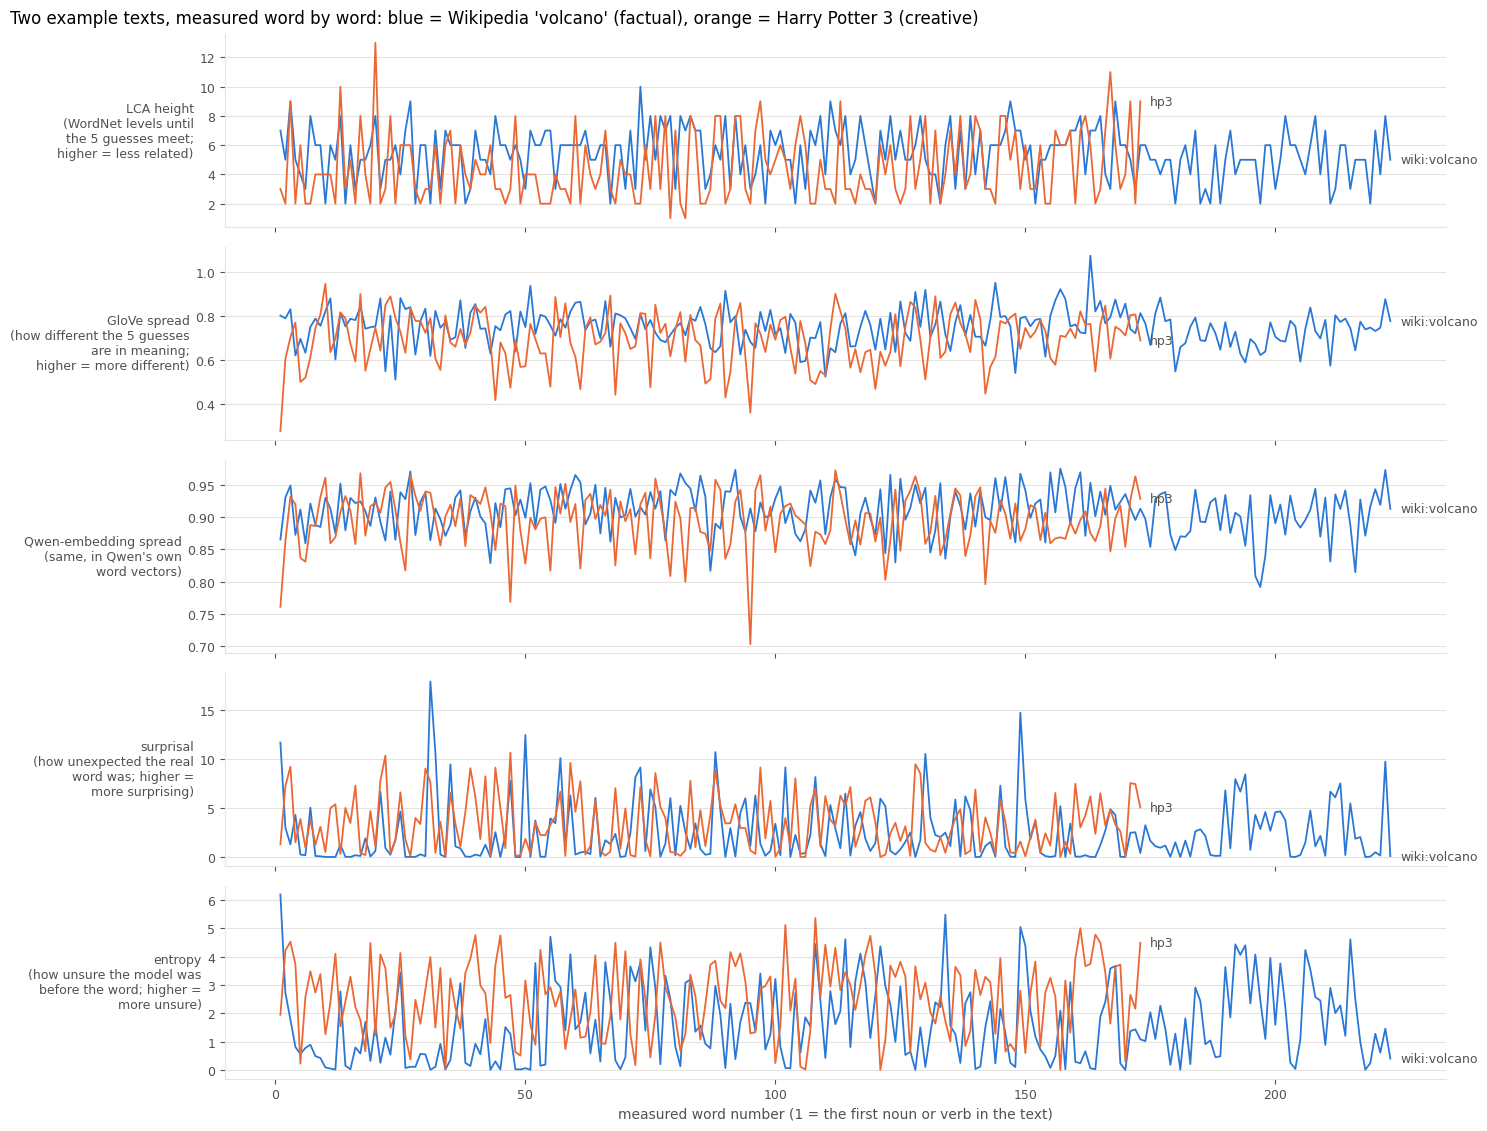

In [4]:
FACTUAL_COLOR = "#2a78d6"     # validated categorical pair (blue / orange)
CREATIVE_COLOR = "#eb6834"
COLORS = {"factual": FACTUAL_COLOR, "creative": CREATIVE_COLOR}
INK = "#52514e"               # secondary text colour
GRID = "#e4e3df"

# what each metric means, in words, for the y axis (direction included)
Y_LABELS = {
    "lca_height": "LCA height\n(WordNet levels until\nthe 5 guesses meet;\nhigher = less related)",
    "glove_mean": "GloVe spread\n(how different the 5 guesses\nare in meaning;\nhigher = more different)",
    "emb_mean": "Qwen-embedding spread\n(same, in Qwen's own\nword vectors)",
    "surprisal": "surprisal\n(how unexpected the real\nword was; higher =\nmore surprising)",
    "entropy": "entropy\n(how unsure the model was\nbefore the word; higher =\nmore unsure)",
    "renyi": "Rényi\n(distance of the model's\nguesses from 'no idea')",
    "self_certainty": "self-certainty\n(LM-Polygraph)",
}


def clean_axes(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color(GRID)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=INK, labelsize=9)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)


EXAMPLES = ["factual_wiki_volcano", "creative_hp3"]
fig, axes = plt.subplots(len(MAIN_WORD_SERIES), 1, figsize=(15, 2.3 * len(MAIN_WORD_SERIES)), sharex=True)
for ax, (column, title) in zip(axes, MAIN_WORD_SERIES.items()):
    for name in EXAMPLES:
        curve = curves_of(words, column)[text_names.index(name)]
        positions = np.arange(1, len(curve) + 1)
        ax.plot(positions, curve, color=COLORS[kind(name)], lw=1.3)
        ax.text(positions[-1] + 2, curve[-1], short(name), color=INK, fontsize=9, va="center")  # direct label
    ax.set_ylabel(Y_LABELS[column], fontsize=9, color=INK, rotation=0, ha="right", va="center")
    clean_axes(ax)
axes[-1].set_xlabel("measured word number (1 = the first noun or verb in the text)", color=INK)
fig.suptitle("Two example texts, measured word by word: blue = Wikipedia 'volcano' (factual), "
             "orange = Harry Potter 3 (creative)", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
save(fig, "1_what_a_curve_is.png")
plt.show()

### 3b. All 25 curves, one small panel per text
The two metrics that separated the texts best (section 5). **One panel = one text**, in the same scale everywhere,
so panels can be compared directly. Top rows: the 12 factual texts (blue); bottom rows: the 13 creative texts
(orange). Look for: does a group of panels share a typical level or rhythm?

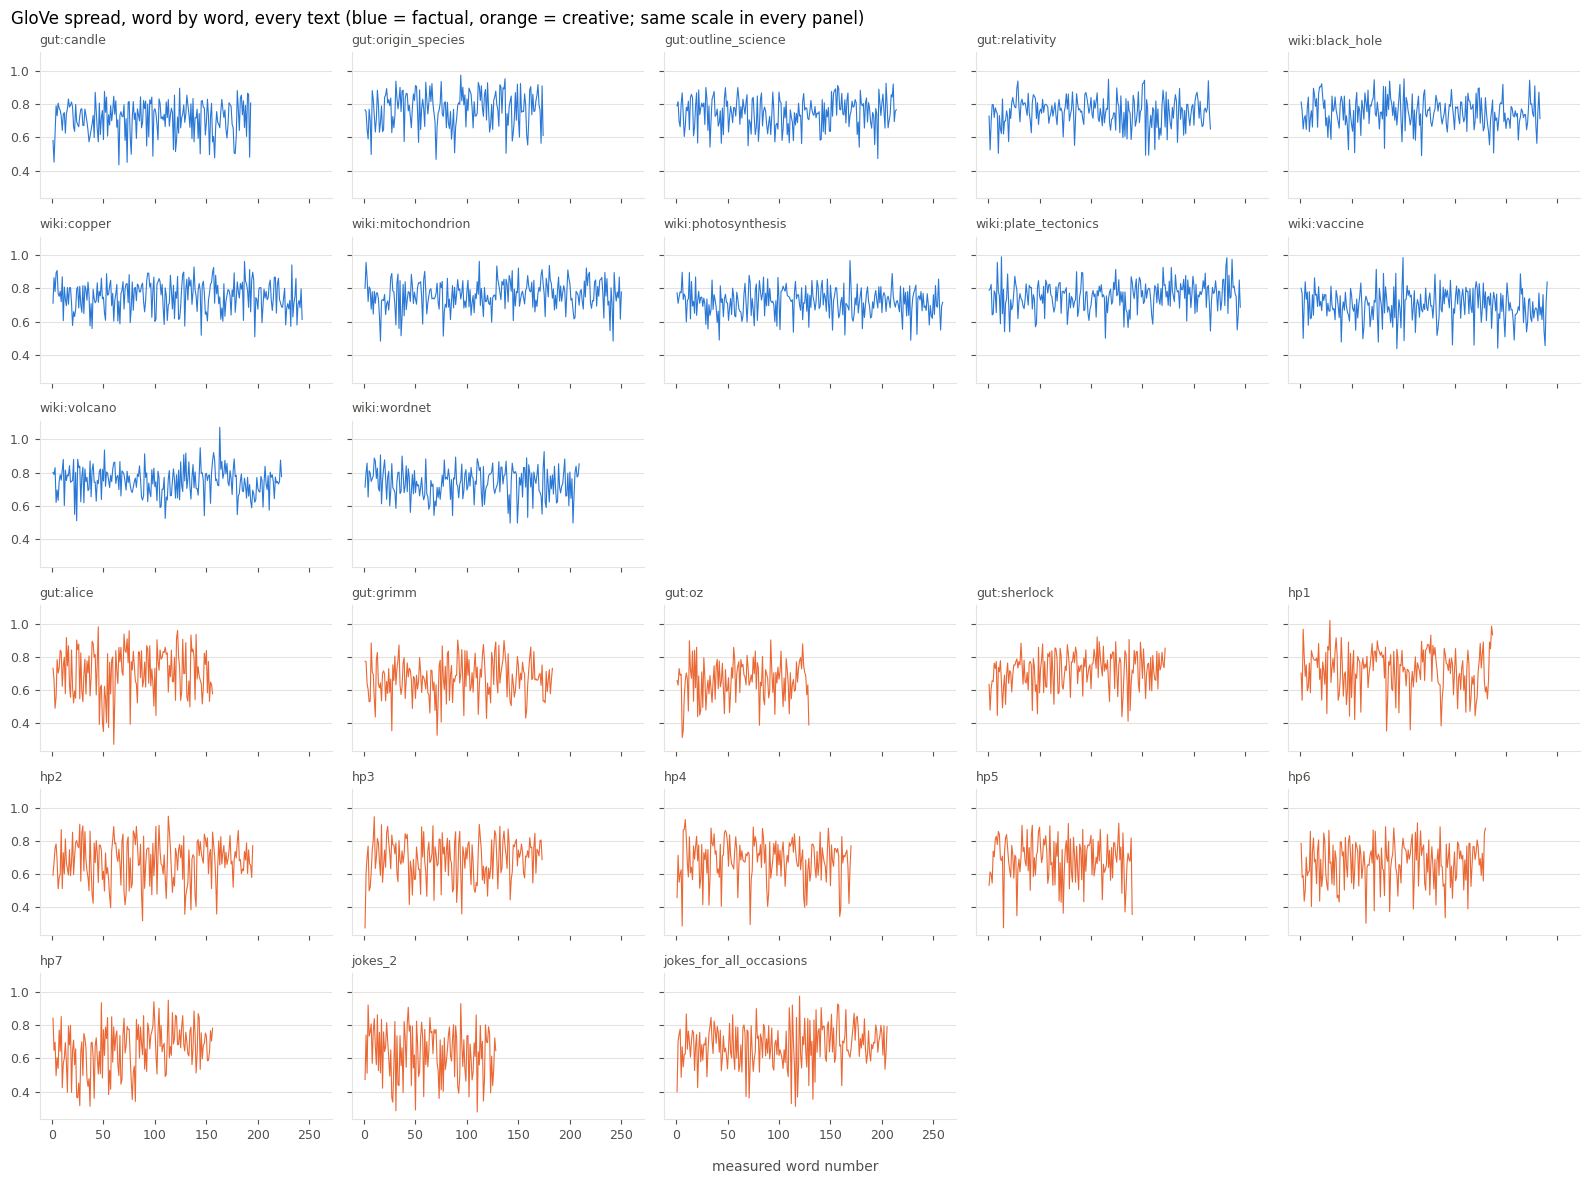

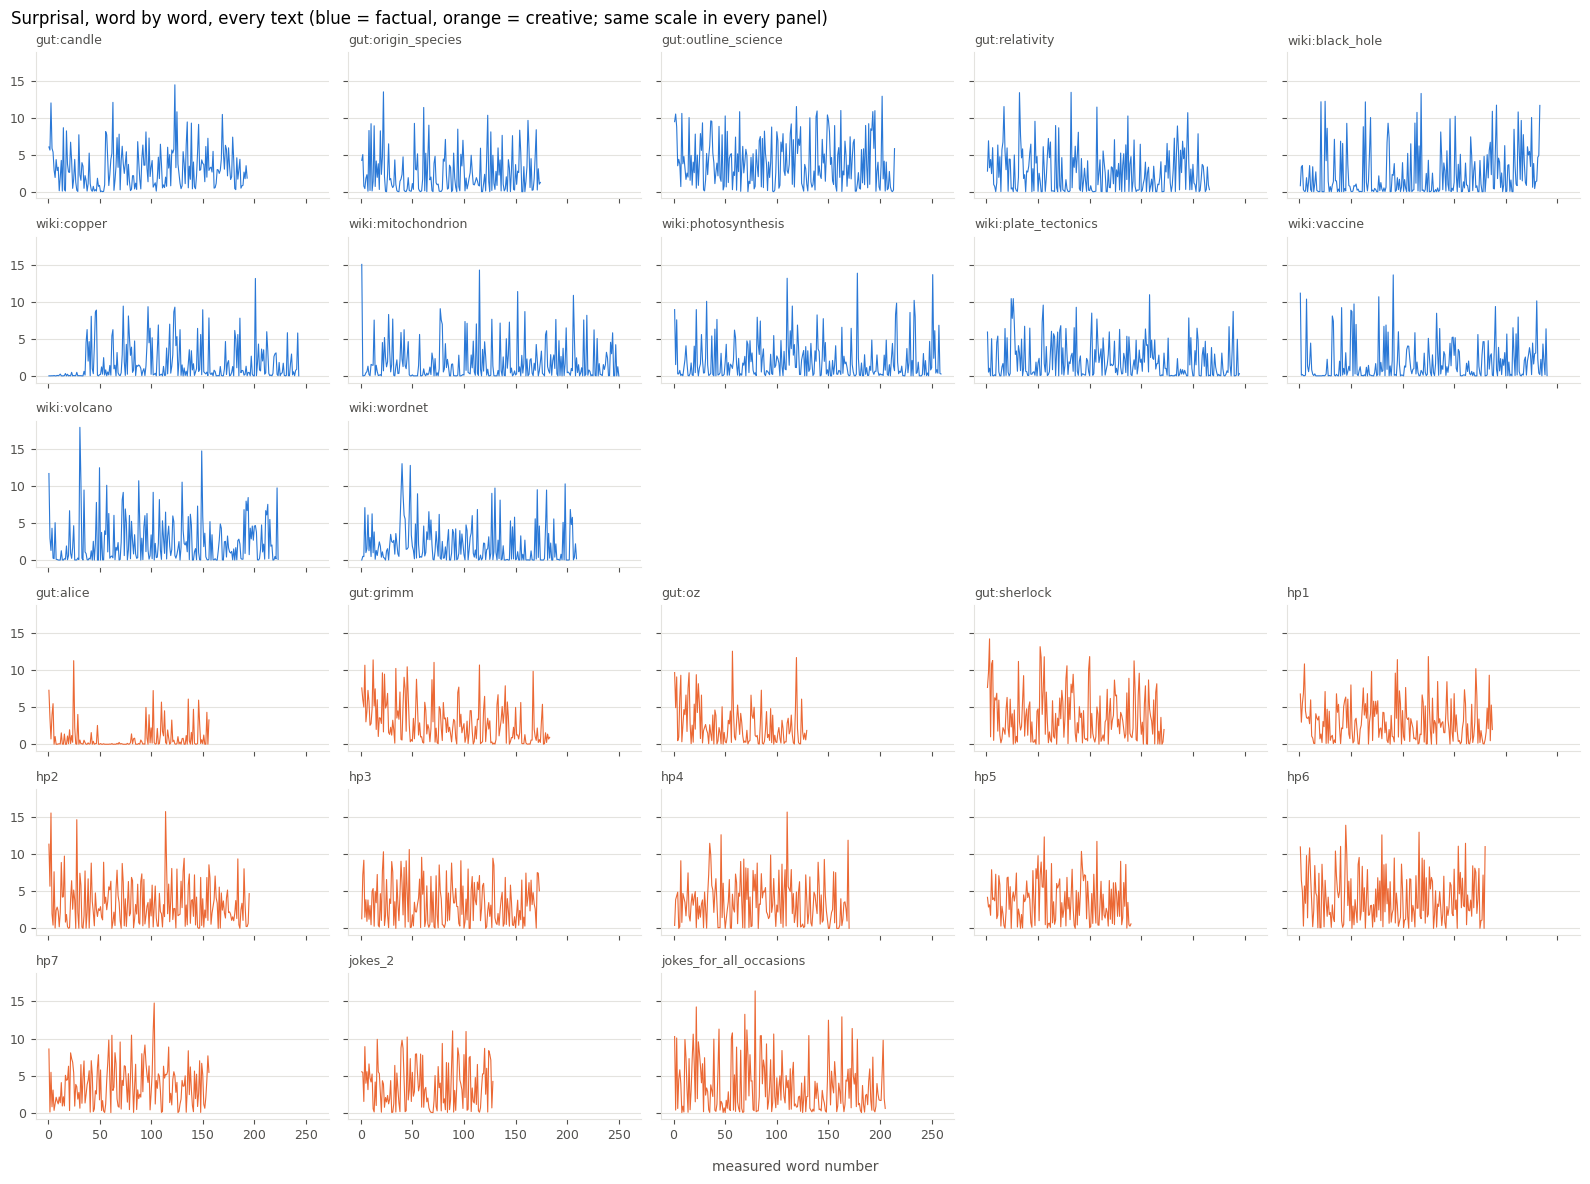

In [5]:
ORDER = sorted(text_names, key=lambda n: (kind(n) != "factual", source(n), n))   # factual first, then by source


def small_multiples(column, title, file_name):
    columns_per_row = 5
    rows = int(np.ceil(len(ORDER) / columns_per_row)) + 1    # +1: start creative texts on a new row
    fig, axes = plt.subplots(rows, columns_per_row, figsize=(16, 2.0 * rows), sharex=True, sharey=True)
    for ax in axes.flat:
        ax.set_visible(False)
    factual_names = [n for n in ORDER if kind(n) == "factual"]
    creative_names = [n for n in ORDER if kind(n) == "creative"]
    slots = list(range(len(factual_names)))
    first_creative_slot = int(np.ceil(len(factual_names) / columns_per_row)) * columns_per_row
    slots += list(range(first_creative_slot, first_creative_slot + len(creative_names)))
    for slot, name in zip(slots, factual_names + creative_names):
        ax = axes.flat[slot]
        ax.set_visible(True)
        curve = curves_of(words, column)[text_names.index(name)]
        ax.plot(np.arange(1, len(curve) + 1), curve, color=COLORS[kind(name)], lw=0.8)
        ax.set_title(short(name), fontsize=9, color=INK, loc="left")
        clean_axes(ax)
    fig.suptitle(f"{title}, word by word, every text (blue = factual, orange = creative; same scale in every panel)",
                 x=0.01, ha="left", fontsize=12)
    fig.supxlabel("measured word number", color=INK, fontsize=10)
    fig.tight_layout()
    save(fig, file_name)
    plt.show()


small_multiples("glove_mean", "GloVe spread", "2_all_texts_glove.png")
small_multiples("surprisal", "Surprisal", "3_all_texts_surprisal.png")

**What to see:**
- **Surprisal:** factual texts have **many words near 0** (about 40% of their measured words are almost certain,
  against about 21% in creative texts), so their occasional high values stand out as isolated spikes. Creative texts
  stay **at a middle level all the way through**, and actually have *more* high-surprise words (about 21% vs 10%).
  This difference in *shape* is what the best run (score 0.84) picks up. Exact numbers: `03_results_explained.ipynb`.
- **GloVe spread:** factual curves stay in a **narrower band** (mostly 0.6–0.9); creative curves **dip lower and more
  often** (the guesses are sometimes very close in meaning), and each creative text looks different from the others.
- ***Alice*** is almost flat at 0 surprisal: the model has very likely memorised it. *wiki:copper* is also flat for its
  first ~30 words (probably a memorised opening paragraph).

### 3c. Do neighbouring words have similar values?
For each text: the correlation between each word's value and the **next** word's value (lag-1 autocorrelation).
**0** = knowing one word's value tells you nothing about the next; **closer to 1** = values come in runs (stretches of
high values, then stretches of low ones). One dot per text.

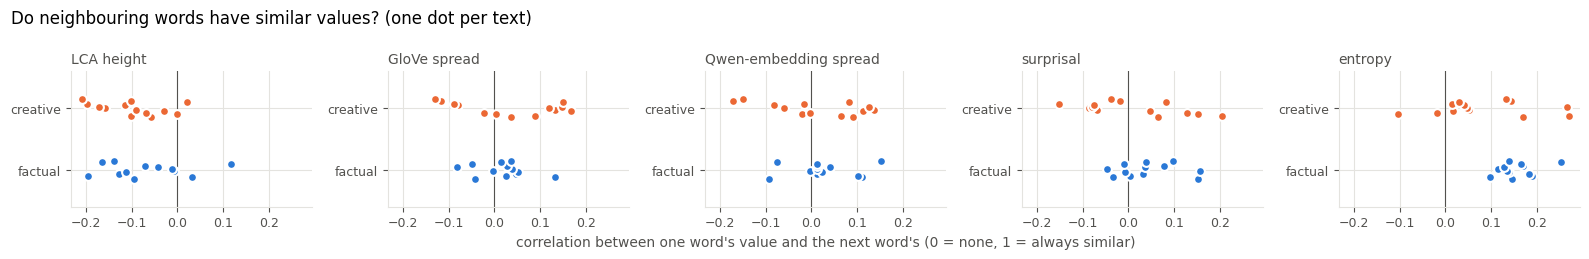

In [6]:
def lag1_correlation(curve):
    return np.corrcoef(curve[:-1], curve[1:])[0, 1]


fig, axes = plt.subplots(1, len(MAIN_WORD_SERIES), figsize=(16, 2.6), sharex=True)
for ax, (column, title) in zip(axes, MAIN_WORD_SERIES.items()):
    curves = curves_of(words, column)
    for row, kind_name in enumerate(["factual", "creative"]):
        values = [lag1_correlation(c) for name, c in zip(text_names, curves) if kind(name) == kind_name]
        jitter = np.linspace(-0.15, 0.15, len(values))
        ax.scatter(values, row + jitter, s=40, color=COLORS[kind_name], edgecolor="white", linewidth=1.5, zorder=3)
    ax.set_yticks([0, 1], ["factual", "creative"])
    ax.set_ylim(-0.6, 1.6)
    ax.axvline(0, color=INK, lw=0.8)
    ax.set_title(title, fontsize=10, color=INK, loc="left")
    clean_axes(ax)
    ax.grid(axis="x", color=GRID, lw=0.8)
axes[2].set_xlabel("correlation between one word's value and the next word's (0 = none, 1 = always similar)",
                   color=INK)
fig.suptitle("Do neighbouring words have similar values? (one dot per text)", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
save(fig, "4_neighbouring_words.png")
plt.show()

**What to see:** almost every dot is between −0.2 and +0.3, i.e. **close to 0**: one word's value says very little
about the next word's. The curves are mostly word-to-word jumps, not slow waves. The only small difference: for
entropy, factual texts lean slightly positive (uncertain words come a little more in runs).

## 4. Distances between whole curves
For each metric, two scalings (raw / standardised per curve) × two distances:
- **DTW** (`tslearn.metrics.cdist_dtw`): lines the two curves up (matched points may be at most 10% of the median
  length apart), then = √(sum of squared differences of the matched points). Works on curves of different lengths.
- **Euclidean**: every curve is first stretched (linear interpolation) to 200 points, then the ordinary
  straight-line distance; point 50 of one text is compared with point 50 of the other (= the same share of the way
  through the text).

Each gives a 25 × 25 table of distances between texts.

In [7]:
def standardise(curve):
    return (curve - curve.mean()) / curve.std()


def stretch(curve, length=STRETCH_LENGTH):
    """Resample a curve to `length` points by linear interpolation over its relative position (0 = start, 1 = end)."""
    old_positions = np.linspace(0, 1, len(curve))
    new_positions = np.linspace(0, 1, length)
    return np.interp(new_positions, old_positions, curve)


def prepared_curves(table_per_text, column, scaling):
    curves = curves_of(table_per_text, column)
    if scaling == "standardised":
        curves = [standardise(c) for c in curves]
    return curves


def dtw_radius(curves):
    return max(1, int(round(WINDOW_SHARE * np.median([len(c) for c in curves]))))


def distance_table(curves, distance):
    if distance == "DTW":
        dataset = to_time_series_dataset(curves)        # pads shorter curves; tslearn ignores the padding
        return cdist_dtw(dataset, global_constraint="sakoe_chiba", sakoe_chiba_radius=dtw_radius(curves))
    stretched = np.array([stretch(c) for c in curves])
    differences = stretched[:, None, :] - stretched[None, :, :]
    return np.sqrt((differences ** 2).sum(axis=-1))


SCALINGS = ["raw", "standardised"]
DISTANCES = ["DTW", "Euclidean"]

## 5. Clustering
For every metric × scaling × distance:
- **DBSCAN** on the distance table. Its distance limit (`eps`) comes from the **k-distance plot**: each text's
  distance to its 3rd-nearest neighbour, sorted; the limit is the "elbow" where the curve bends up (taken as the
  point farthest from the straight line between the first and last value). Texts in no group = **noise**.
- **KMeans** (k = 2) on the stretched curves (needs equal lengths; Euclidean only). Centre = average stretched curve.
- **DTW-KMeans** (k = 2, `tslearn.clustering.TimeSeriesKMeans`, same DTW window). Centre = DTW-aligned average (DBA).
- **k-medoids** (k = 2) on the distance table: every possible pair of texts is tried as the two centres and the pair
  with the smallest total distance wins (exact, 300 pairs for 25 texts). No averaging: centres are real texts.

**ARI** compares clusters with factual/creative (1 = perfect, 0 = no better than random). **Silhouette** (−1 to 1)
says how well separated the clusters are (computed on the same distance table; noise excluded).

In [8]:
def k_distance_elbow(table, k=MIN_SAMPLES):
    """Sorted distance of every text to its k-th nearest other text, and the elbow value used as DBSCAN's eps."""
    kth = []
    for row in table:
        others = np.sort(row)[1:]                        # skip the distance of a text to itself (0)
        kth.append(others[k - 1])
    kth = np.sort(np.array(kth))
    positions = np.arange(len(kth))
    # distance of every point from the straight line between the first and last point; the largest = the elbow
    start = np.array([0, kth[0]])
    end = np.array([len(kth) - 1, kth[-1]])
    line = (end - start) / np.linalg.norm(end - start)
    points = np.column_stack([positions, kth]) - start
    from_line = np.abs(points[:, 0] * line[1] - points[:, 1] * line[0])
    return kth, kth[int(np.argmax(from_line))]


def k_medoids_pairs(table):
    """Exact k-medoids for k = 2: the pair of texts that, as the two centres, gives the smallest total distance."""
    best_cost, best_labels = None, None
    for a, b in combinations(range(len(table)), 2):
        nearest_is_b = table[:, b] < table[:, a]
        cost = np.where(nearest_is_b, table[:, b], table[:, a]).sum()
        if best_cost is None or cost < best_cost:
            best_cost, best_labels = cost, nearest_is_b.astype(int)
    return best_labels


def silhouette_or_nan(table, cluster_labels):
    keep = cluster_labels != -1
    if len(set(cluster_labels[keep])) < 2:
        return np.nan
    return silhouette_score(table[keep][:, keep], cluster_labels[keep], metric="precomputed")


def describe_clusters(cluster_labels):
    """e.g. '0: 10 creative (hp 7, gut 3) + 2 factual | 1: ...'"""
    parts = []
    for cluster in sorted(set(cluster_labels)):
        members = cluster_labels == cluster
        kinds = pd.Series(labels[members]).value_counts().to_dict()
        name = "noise" if cluster == -1 else str(cluster)
        parts.append(f"{name}: " + ", ".join(f"{count} {k}" for k, count in kinds.items()))
    return " | ".join(parts)


def run_all(table_per_text, series, axis_name):
    rows = []
    assignments = {}
    for column, title in series.items():
        for scaling in SCALINGS:
            curves = prepared_curves(table_per_text, column, scaling)
            for distance in DISTANCES:
                table = distance_table(curves, distance)
                kth, eps = k_distance_elbow(table)
                results = {"DBSCAN": DBSCAN(eps=eps, min_samples=MIN_SAMPLES, metric="precomputed").fit_predict(table),
                           "k-medoids": k_medoids_pairs(table)}
                if distance == "Euclidean":
                    stretched = np.array([stretch(c) for c in curves])
                    results["KMeans"] = KMeans(n_clusters=K, n_init=50, random_state=0).fit_predict(stretched)
                else:
                    dataset = to_time_series_dataset(curves)
                    dtw_kmeans = TimeSeriesKMeans(n_clusters=K, metric="dtw", random_state=0, n_init=3, max_iter=30,
                                                  metric_params={"global_constraint": "sakoe_chiba",
                                                                 "sakoe_chiba_radius": dtw_radius(curves)})
                    results["DTW-KMeans"] = dtw_kmeans.fit_predict(dataset)
                for method, cluster_labels in results.items():
                    cluster_labels = np.asarray(cluster_labels)
                    rows.append({"axis": axis_name, "metric": title, "scaling": scaling, "distance": distance,
                                 "method": method, "ARI": adjusted_rand_score(labels, cluster_labels),
                                 "silhouette": silhouette_or_nan(table, cluster_labels),
                                 "clusters": len(set(cluster_labels) - {-1}),
                                 "noise": int((cluster_labels == -1).sum()),
                                 "groups": describe_clusters(cluster_labels)})
                    assignments[(axis_name, title, scaling, distance, method)] = cluster_labels
    return pd.DataFrame(rows), assignments


word_results, word_assignments = run_all(words, WORD_SERIES, "measured word")
token_results, token_assignments = run_all(tokens, TOKEN_SERIES, "token")
results = pd.concat([word_results, token_results], ignore_index=True)
print(len(results), "clusterings")

# save for 03_results_explained.ipynb: every run's scores, and which cluster each text got in each run
results.to_csv(HERE / "results" / "clustering_runs.csv", index=False)
assignment_rows = []
for (axis_name, metric, scaling, distance, method), cluster_labels in {**word_assignments, **token_assignments}.items():
    for name, cluster in zip(text_names, cluster_labels):
        assignment_rows.append({"axis": axis_name, "metric": metric, "scaling": scaling, "distance": distance,
                                "method": method, "text": name, "cluster": int(cluster)})
pd.DataFrame(assignment_rows).to_csv(HERE / "results" / "cluster_assignments.csv", index=False)

108 clusterings


### 5a. Per measured word

In [9]:
pd.set_option("display.max_colwidth", 120)
word_results.round(2)

,axis,metric,scaling,distance,method,ARI,silhouette,clusters,noise,groups
0,measured word,LCA height,raw,DTW,DBSCAN,0.11,NaN,1,4,"noise: 4 factual | 0: 13 creative, 8 factual"
1,measured word,LCA height,raw,DTW,k-medoids,0.06,0.18,2,0,"0: 13 creative, 9 factual | 1: 3 factual"
2,measured word,LCA height,raw,DTW,DTW-KMeans,0.69,0.06,2,0,"0: 11 factual, 1 creative | 1: 12 creative, 1 factual"
3,measured word,LCA height,raw,Euclidean,DBSCAN,0.03,NaN,1,2,"noise: 2 factual | 0: 13 creative, 10 factual"
4,measured word,LCA height,raw,Euclidean,k-medoids,0.01,0.17,2,0,"0: 1 factual | 1: 13 creative, 11 factual"
...,...,...,...,...,...,...,...,...,...,...
67,measured word,Rényi,standardised,DTW,k-medoids,0.24,0.06,2,0,"0: 10 creative, 3 factual | 1: 9 factual, 3 creative"
68,measured word,Rényi,standardised,DTW,DTW-KMeans,-0.03,0.03,2,0,"0: 6 creative, 4 factual | 1: 8 factual, 7 creative"
69,measured word,Rényi,standardised,Euclidean,DBSCAN,-0.01,NaN,1,5,"noise: 3 factual, 2 creative | 0: 11 creative, 9 factual"
70,measured word,Rényi,standardised,Euclidean,k-medoids,0.04,0.02,2,0,"0: 9 factual, 6 creative | 1: 7 creative, 3 factual"


### 5b. Per token (LM-Polygraph values)

In [10]:
token_results.round(2)

,axis,metric,scaling,distance,method,ARI,silhouette,clusters,noise,groups
0,token,surprisal,raw,DTW,DBSCAN,0.09,NaN,1,9,"noise: 7 creative, 2 factual | 0: 10 factual, 6 creative"
1,token,surprisal,raw,DTW,k-medoids,-0.03,0.04,2,0,"0: 6 factual, 5 creative | 1: 8 creative, 6 factual"
2,token,surprisal,raw,DTW,DTW-KMeans,0.02,0.04,2,0,"0: 3 factual, 1 creative | 1: 12 creative, 9 factual"
3,token,surprisal,raw,Euclidean,DBSCAN,0.05,NaN,1,6,"noise: 5 creative, 1 factual | 0: 11 factual, 8 creative"
4,token,surprisal,raw,Euclidean,k-medoids,0.24,0.02,2,0,"0: 9 factual, 3 creative | 1: 10 creative, 3 factual"
5,token,surprisal,raw,Euclidean,KMeans,-0.02,0.10,2,0,"0: 2 creative, 1 factual | 1: 11 creative, 11 factual"
6,token,surprisal,standardised,DTW,DBSCAN,0.00,NaN,1,2,"noise: 2 creative | 0: 12 factual, 11 creative"
7,token,surprisal,standardised,DTW,k-medoids,0.11,0.03,2,0,"0: 13 creative, 8 factual | 1: 4 factual"
8,token,surprisal,standardised,DTW,DTW-KMeans,0.02,0.05,2,0,"0: 3 factual, 1 creative | 1: 12 creative, 9 factual"
9,token,surprisal,standardised,Euclidean,DBSCAN,-0.03,NaN,1,11,"noise: 6 factual, 5 creative | 0: 8 creative, 6 factual"


### 5c. Which metric separates factual from creative best?
One bar per metric: its **best score** over all its runs (raw or shape-only × DTW or Euclidean × the 4 clustering
methods). The label says which run that was.

**How to read it:** the score is ARI: **0 = no better than random**, **1 = the clusters are exactly factual vs
creative**. Top panel: measured per noun/verb; bottom panel: measured per token.

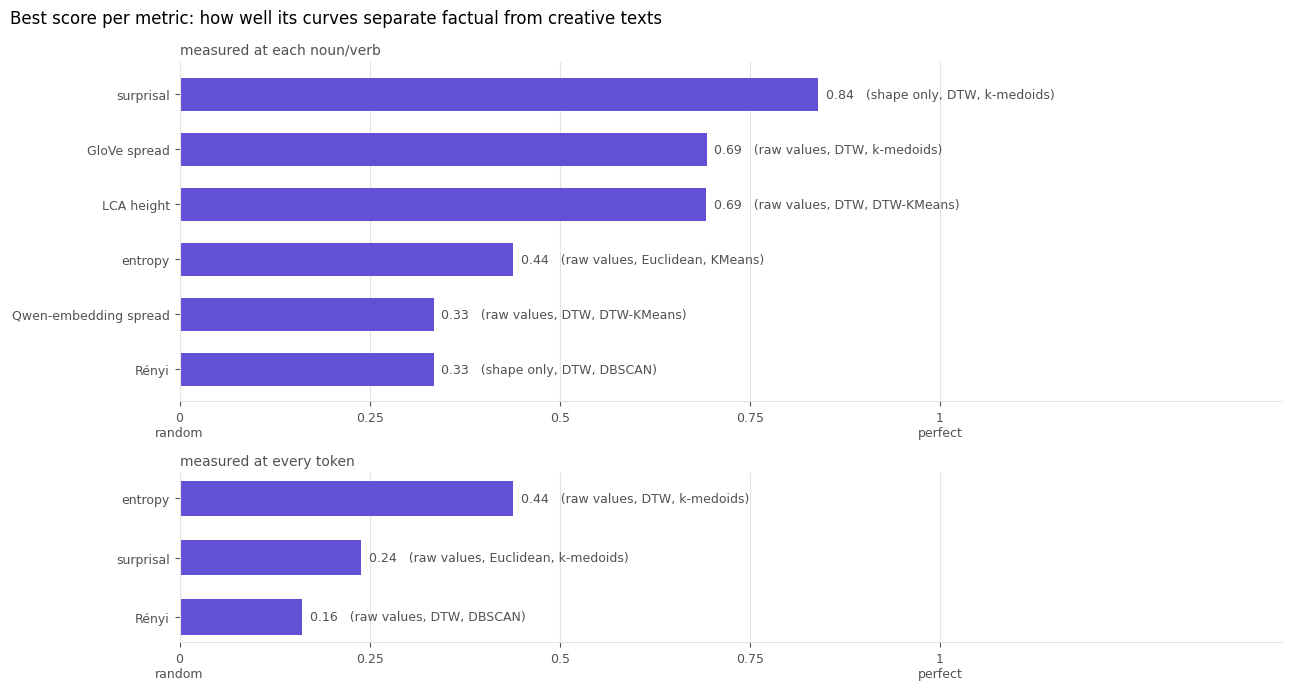

In [11]:
SCORE_COLOR = "#6250d6"   # one series -> one hue (not the factual/creative colours)

best_per_metric = (results.sort_values("ARI", ascending=False)
                   .groupby(["axis", "metric"], as_index=False).first())


def run_label(run):
    scaling = "shape only" if run["scaling"] == "standardised" else "raw values"
    return f"{run['ARI']:.2f}   ({scaling}, {run['distance']}, {run['method']})"


axis_order = ["measured word", "token"]
heights = [len(best_per_metric[best_per_metric["axis"] == a]) for a in axis_order]
fig, axes = plt.subplots(2, 1, figsize=(13, 0.5 * sum(heights) + 2.5), gridspec_kw={"height_ratios": heights})
for ax, axis_name in zip(axes, axis_order):
    rows = best_per_metric[best_per_metric["axis"] == axis_name].sort_values("ARI")
    y = np.arange(len(rows))
    ax.barh(y, rows["ARI"].clip(lower=0), height=0.6, color=SCORE_COLOR)
    for position, (_, run) in zip(y, rows.iterrows()):
        ax.text(max(run["ARI"], 0) + 0.01, position, run_label(run), va="center", fontsize=9, color=INK)
    ax.set_yticks(y, rows["metric"], fontsize=10)
    ax.set_xlim(0, 1.45)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0], ["0\nrandom", "0.25", "0.5", "0.75", "1\nperfect"])
    panel_name = {"measured word": "measured at each noun/verb", "token": "measured at every token"}[axis_name]
    ax.set_title(panel_name, loc="left", fontsize=10, color=INK)
    clean_axes(ax)
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.grid(axis="y", visible=False)
fig.suptitle("Best score per metric: how well its curves separate factual from creative texts",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
save(fig, "5_best_score_per_metric.png")
plt.show()

### 5d. The three best runs: which texts ended up together?
For the best run of each of the three top metrics. **Each column is one cluster** the algorithm made (DBSCAN can also
leave texts in **no cluster** = "noise": texts that are not close to any group). Each text is written in its own
colour: **blue = factual, orange = creative**. A perfect result = one column all blue, the other all orange.

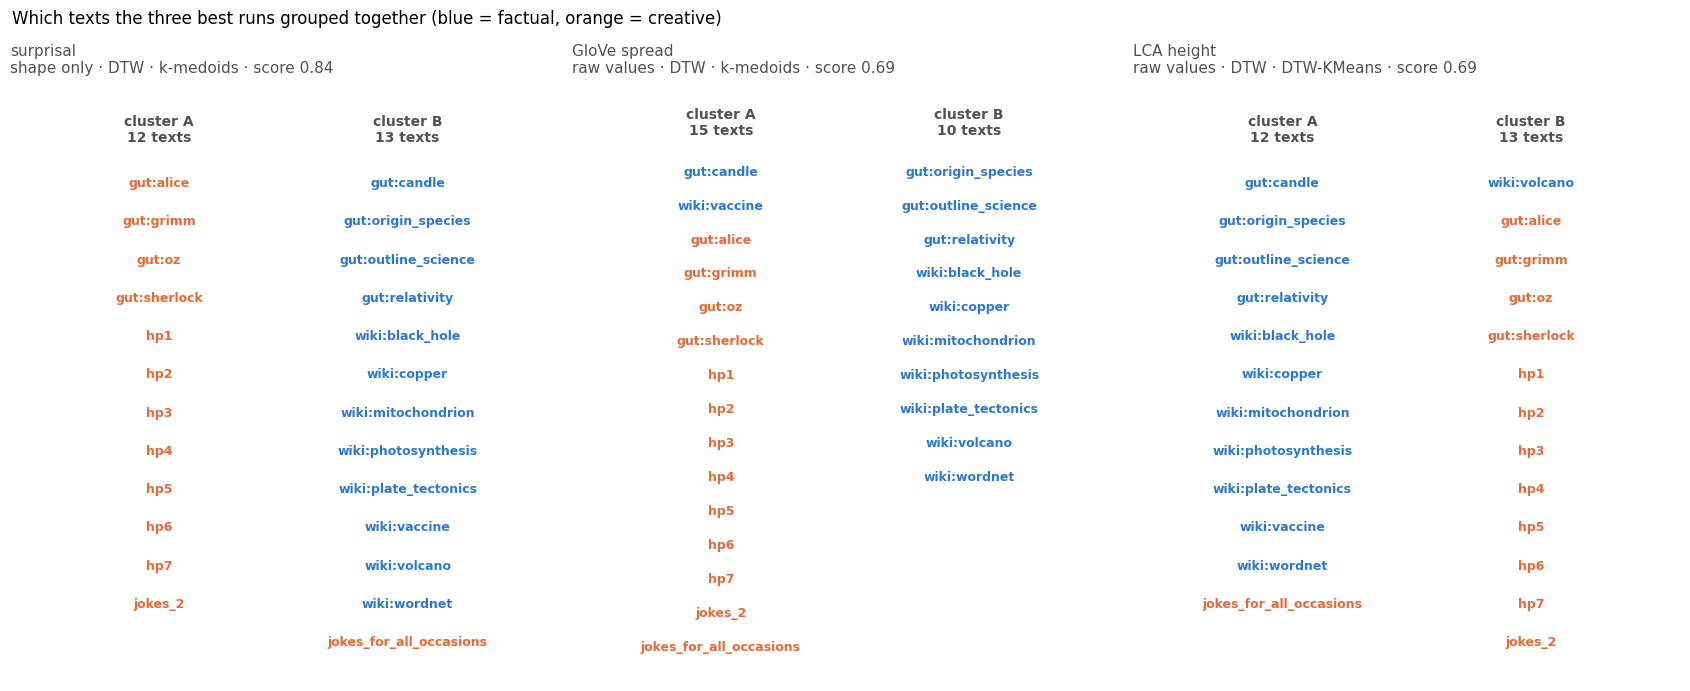

In [12]:
top_runs = []
for _, run in results.sort_values("ARI", ascending=False).iterrows():
    if run["metric"] not in [r["metric"] for r in top_runs]:
        top_runs.append(run)
    if len(top_runs) == 3:
        break
all_assignments = {**word_assignments, **token_assignments}


def cluster_columns(ax, cluster_labels):
    clusters = sorted(set(cluster_labels), key=lambda c: (c == -1, c))
    for column_index, cluster in enumerate(clusters):
        members = [n for n, c in zip(text_names, cluster_labels) if c == cluster]
        members.sort(key=lambda n: (kind(n) != "factual", source(n), n))
        heading = "no cluster (noise)" if cluster == -1 else f"cluster {chr(ord('A') + column_index)}"
        ax.text(column_index, 0, f"{heading}\n{len(members)} texts", ha="center", va="bottom", fontsize=10,
                color=INK, fontweight="bold")
        for row, name in enumerate(members, start=1):
            ax.text(column_index, -row * 0.9, short(name), ha="center", va="center", fontsize=9,
                    color=COLORS[kind(name)], fontweight="bold")
    biggest = max(int((np.asarray(cluster_labels) == c).sum()) for c in clusters)
    ax.set_xlim(-0.6, len(clusters) - 0.4)
    ax.set_ylim(-(biggest + 1) * 0.9, 1.5)
    ax.axis("off")


fig, axes = plt.subplots(1, 3, figsize=(17, 7))
for ax, run in zip(axes, top_runs):
    key = (run["axis"], run["metric"], run["scaling"], run["distance"], run["method"])
    cluster_columns(ax, all_assignments[key])
    scaling = "shape only" if run["scaling"] == "standardised" else "raw values"
    ax.set_title(f"{run['metric']}\n{scaling} · {run['distance']} · {run['method']} · score {run['ARI']:.2f}",
                 fontsize=11, color=INK, loc="left")
fig.suptitle("Which texts the three best runs grouped together (blue = factual, orange = creative)",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
save(fig, "6_who_went_where.png")
plt.show()

### 5e. A map of the texts
The same three runs as a map: the 25 × 25 table of distances between curves, laid out flat (multidimensional
scaling) so that **texts with similar curves sit close together** and very different ones far apart. Colour = true
kind; marker = the cluster the algorithm chose (× = no cluster). The axes have no units: only distances matter.
The flat map is an approximation of the full distance table, so a text can sit near the other group on the map and
still belong to its own cluster (the clustering used the full table).

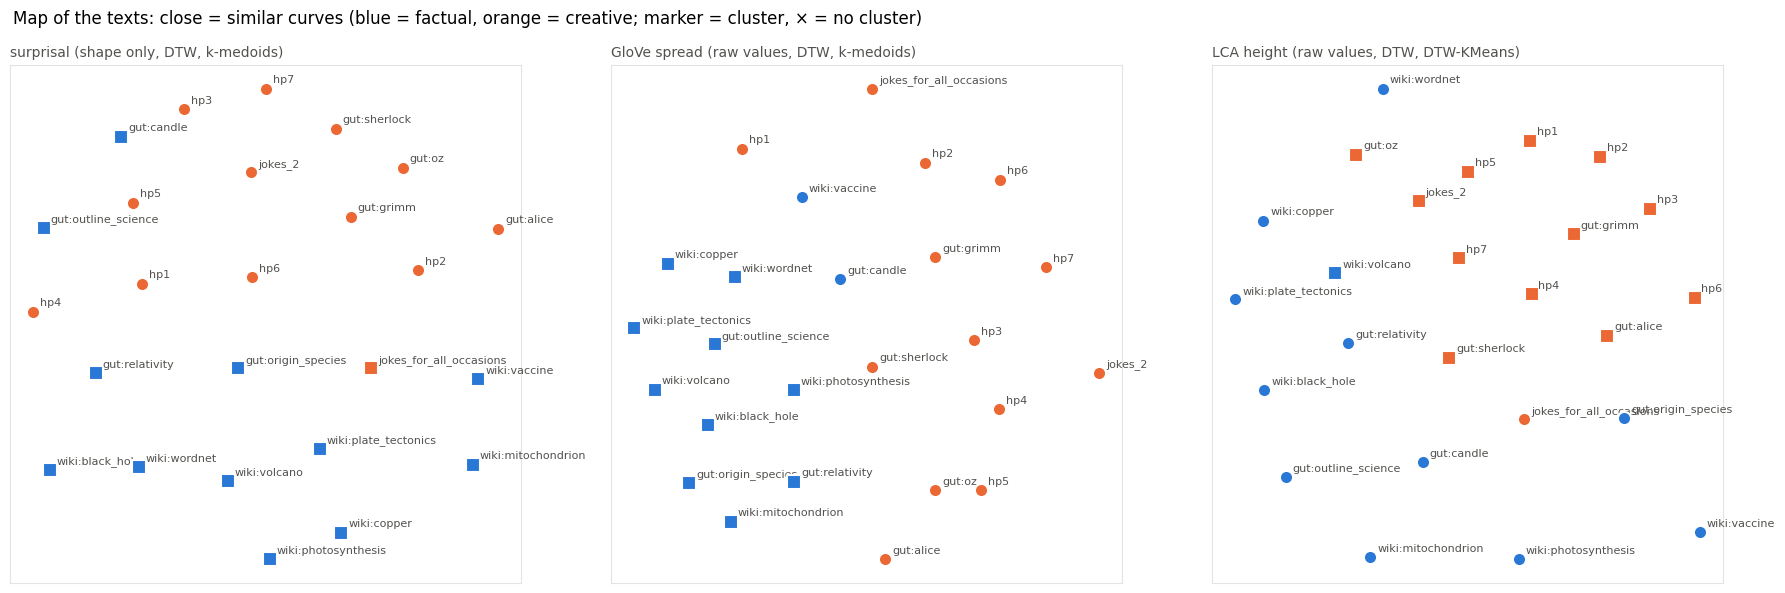

In [13]:
from sklearn.manifold import MDS

MARKERS = {0: "o", 1: "s", 2: "^", -1: "X"}
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, run in zip(axes, top_runs):
    table_per_text = words if run["axis"] == "measured word" else tokens
    column = {title: c for c, title in {**WORD_SERIES, **TOKEN_SERIES}.items()}[run["metric"]]
    table = distance_table(prepared_curves(table_per_text, column, run["scaling"]), run["distance"])
    layout = MDS(n_components=2, dissimilarity="precomputed", random_state=0).fit_transform(table)
    key = (run["axis"], run["metric"], run["scaling"], run["distance"], run["method"])
    cluster_labels = all_assignments[key]
    for i, name in enumerate(text_names):
        ax.scatter(layout[i, 0], layout[i, 1], s=90, marker=MARKERS.get(cluster_labels[i], "o"),
                   color=COLORS[kind(name)], edgecolor="white", linewidth=1.5, zorder=3)
        ax.annotate(short(name), layout[i], fontsize=8, color=INK, xytext=(5, 4), textcoords="offset points")
    scaling = "shape only" if run["scaling"] == "standardised" else "raw values"
    ax.set_title(f"{run['metric']} ({scaling}, {run['distance']}, {run['method']})", fontsize=10, color=INK,
                 loc="left")
    ax.set_xticks([])
    ax.set_yticks([])
    for side in ax.spines.values():
        side.set_color(GRID)
fig.suptitle("Map of the texts: close = similar curves (blue = factual, orange = creative; "
             "marker = cluster, × = no cluster)", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
save(fig, "7_map_of_texts.png")
plt.show()

### 5f. Sensitivity: DTW window 5% / 10% / 20%
ARI of k-medoids and DBSCAN on DTW distances (per measured word, raw and standardised) for three window sizes.
If the numbers barely move, the 10% choice doesn't matter much.

In [14]:
rows = []
for share in [0.05, 0.10, 0.20]:
    WINDOW_SHARE = share
    for column, title in MAIN_WORD_SERIES.items():
        for scaling in SCALINGS:
            table = distance_table(prepared_curves(words, column, scaling), "DTW")
            kth, eps = k_distance_elbow(table)
            rows.append({"window": f"{share:.0%}", "metric": title, "scaling": scaling,
                         "k-medoids ARI": adjusted_rand_score(labels, k_medoids_pairs(table)),
                         "DBSCAN ARI": adjusted_rand_score(labels, DBSCAN(eps=eps, min_samples=MIN_SAMPLES,
                                                                          metric="precomputed").fit_predict(table))})
WINDOW_SHARE = 0.10
sensitivity = pd.DataFrame(rows)
sensitivity.pivot_table(index=["metric", "scaling"], columns="window",
                        values=["k-medoids ARI", "DBSCAN ARI"]).round(2)

DBSCAN ARI             k-medoids ARI        \
window                                    10%   20%    5%           10%   20%   
metric                scaling                                                   
GloVe spread          raw                0.69  0.69  0.69          0.69  0.69   
                      standardised       0.56  0.33  0.44          0.01  0.06   
LCA height            raw                0.11  0.11  0.11          0.06  0.25   
                      standardised       0.56  0.56  0.56          0.56  0.56   
Qwen-embedding spread raw                0.10  0.10  0.10          0.04  0.04   
                      standardised       0.24  0.24  0.84          0.01  0.01   
entropy               raw               -0.02 -0.03 -0.03          0.01 -0.01   
                      standardised       0.11  0.17  0.06          0.09  0.09   
surprisal             raw               -0.02 -0.02 -0.02          0.56  0.17   
                      standardised       0.24  0.34  0.16          0.84  0.69   

                                          
window                                5%  
metric                scaling             
GloVe spread          raw           0.69  
                      standardised  0.01  
LCA height            raw           0.01  
                      standardised  0.56  
Qwen-embedding spread raw           0.24  
                      standardised  0.01  
entropy               raw           0.01  
                      standardised  0.09  
surprisal             raw           0.44  
                      standardised  0.69

## 6. Findings (25 texts, Qwen2.5-7B-Instruct, 4-bit)

**ARI**: 1 = clusters are exactly factual vs creative, 0 = random. **Silhouette**: how well separated (−1 to 1).

| run | ARI | what happened |
|---|---|---|
| **surprisal, standardised, per measured word, DTW, k-medoids** | **0.84** | 24 of 25 texts right, including all 8 Gutenberg texts; only one joke book lands with the factual texts. But silhouette is only 0.04 (the two groups touch), the other methods on the same distances score 0.11–0.24, and other DTW windows give 0.69. |
| **GloVe spread, raw, per measured word, DTW** (DBSCAN, DTW-KMeans and k-medoids alike) | **0.69** | Stable across methods and all three DTW windows. DBSCAN shows *why*: 10 of the 12 factual texts form one dense group, and **every creative text is "noise"**: the factual curves resemble each other, the creative curves each differ from all others. |
| LCA height, standardised (shape), DTW | 0.56 | the same with DBSCAN, DTW-KMeans and k-medoids, and at every window |
| everything per token (LM-Polygraph values on all ~900 tokens) | ≤ 0.44 | much weaker than the same values per measured word |

1. **Comparing whole raw curves works for some metrics.** The most consistent result is GloVe spread: factual texts have
   similar curves, creative texts are each different (no dense creative group at all).
2. **Surprisal's curve shape gives the best single split (0.84)**, and it holds on the Gutenberg texts, which come from a
   different site and era than the Wikipedia / Harry Potter texts. But it depends on the method and window, so treat it
   as promising, not settled.
3. **DTW beats stretched Euclidean** in most rows: lining up the curves' ups and downs matters.
4. **Per-token series are weak.** Most tokens are function words, word pieces and punctuation, which bury the signal;
   measuring at nouns/verbs works better.
5. **Memorisation.** *Alice in Wonderland* has a mean surprisal of 0.63 (other fiction ≈ 2): the model has very likely
   memorised it, so its curves describe recall, not reading.

**Caveats:** 25 texts; raw GloVe spread is partly word rarity (rarer, more technical words in factual texts), which was
not corrected here by choice; the 4-bit model adds small rounding noise (mean 0.03 in surprisal).